In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import sys
import os

from pathlib import Path
cwd = Path.cwd()

if (cwd / "notebooks").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "notebooks").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Cannot find utils/ directory")

sys.path.insert(0, str(PROJECT_ROOT))

NOTEBOOK_DIR    = PROJECT_ROOT / "notebooks"            # .../uk-house-prices/data
DATA_RAW_DIR    = PROJECT_ROOT / "data" / "raw"         # .../uk-house-prices/data/raw
DATA_PRO_DIR    = PROJECT_ROOT / "data" / "processed"   # .../uk-house-prices/data/processed

from utils.read_multi_table_csv import read_multi_table_csv
from utils.read_xlsx_range import read_xlsx_range

In [ ]:
# Import Price Paid yearly (2023) from HM Land Registry
# Assign column names

price_paid = pd.read_csv(
    DATA_RAW_DIR / 'pp-2023.csv',
    header = None,
    names = [
        "transaction ID",
        "price",
        "date of transfer",
        "postcode",
        "property type",
        "new build",
        "duration",
        "PAON",
        "SAON",
        "street",
        "locality",
        "town/city",
        "district",
        "county",
        "PPD category",
        "record status"
    ]
)

In [ ]:
# print(price_paid[:][1:20].to_string())

# pd.unique(price_paid["PPD category"])
# pd.unique(price_paid["record status"])

# price_paid["PPD category"].value_counts()
price_paid.query("price > 100000000")

,transaction ID,price,date of transfer,postcode,property type,new build,duration,PAON,SAON,street,locality,town/city,district,county,PPD category,record status
8218,{01EB45F0-74C4-40F3-E063-4704A8C05FDE},134500000,2023-06-20 00:00,N17 9FD,O,N,F,A102 EMILY BOWES COURT,NaN,LEBUS STREET,NaN,LONDON,HARINGEY,GREATER LONDON,B,A
8402,{0E082197-6088-5C09-E063-4704A8C0A10E},110000000,2023-06-13 00:00,W3 6FW,O,N,F,200,NaN,WESTERN AVENUE,NaN,LONDON,EALING,GREATER LONDON,B,A
16581,{06C9F487-FA79-9388-E063-4804A8C0BD98},120250000,2023-01-10 00:00,SL1 4DX,O,N,F,BATH ROAD RETAIL PARK,NaN,BATH ROAD,NaN,SLOUGH,SLOUGH,SLOUGH,B,A
77985,{2D4D7609-ECD9-BDF9-E063-4804A8C0672F},115000000,2023-12-14 00:00,CR0 2WF,O,N,L,1,NaN,RUSKIN SQUARE,NaN,CROYDON,CROYDON,GREATER LONDON,B,A
106751,{045A1899-60A3-9A24-E063-4804A8C048EA},101790000,2023-08-03 00:00,EC3N 2EJ,O,N,F,FRIARY COURT,NaN,NORTHUMBERLAND ALLEY,NaN,LONDON,CITY OF LONDON,GREATER LONDON,B,A
216214,{2131FCF6-BFF8-86E8-E063-4804A8C0372B},267500000,2023-06-01 00:00,W1S 2YF,O,N,L,WESTBURY HOTEL,GROUND FLOOR PREMISES,CONDUIT STREET,NaN,LONDON,CITY OF WESTMINSTER,GREATER LONDON,B,A
218211,{2131FCF6-C03A-86E8-E063-4804A8C0372B},267500000,2023-06-01 00:00,W1S 2YF,O,N,L,"WESTBURY HOTEL, 37",GROUND FLOOR PREMISES,CONDUIT STREET,NaN,LONDON,CITY OF WESTMINSTER,GREATER LONDON,B,A
228316,{0E082197-6AF5-5C09-E063-4704A8C0A10E},110255123,2023-09-22 00:00,E14 5SP,O,N,F,2,NaN,TRAFALGAR WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,B,A
236863,{0E082197-77FA-5C09-E063-4704A8C0A10E},249500000,2023-09-28 00:00,EC1V 4EX,O,N,F,"ANGEL BUILDING, 407",NaN,ST JOHN STREET,NaN,LONDON,ISLINGTON,GREATER LONDON,B,A
239016,{2131FCF6-CD24-86E8-E063-4804A8C0372B},132036715,2023-11-10 00:00,BN1 2TF,O,N,F,UNIT 87,NaN,CHURCHILL SQUARE,NaN,BRIGHTON,BRIGHTON AND HOVE,BRIGHTON AND HOVE,B,A


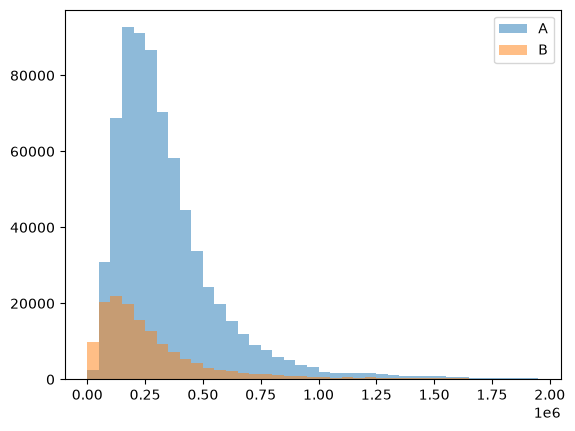

In [37]:
ppd_A = price_paid.loc[price_paid["PPD category"] == "A"]["price"].to_numpy()
ppd_B = price_paid.loc[price_paid["PPD category"] == "B"]["price"].to_numpy()

plt.hist(ppd_A, bins = np.arange(0, 2000000, 50000), alpha = 0.5, label = "A")
plt.hist(ppd_B, bins = np.arange(0, 2000000, 50000), alpha = 0.5, label = "B")
plt.legend()
plt.show()

In [ ]:
# Import qualifications data from census 2021

# Tables:
    # Total
    # Economically active (excluding full-time students): In employment 
    # Economically active (excluding full-time students): Unemployed 
    # Economically active and a full-time student: In employment 
    # Economically active and a full-time student: Unemployed 
    # Economically inactive (excluding full-time students) 
    # Economically inactive and a full-time student 

qualifications = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-RM048 - Highest level of qualification by economic activity status.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)
# for table_name, df in qualifications.items():
#     print(table_name, "\n")
#     print(df)

In [ ]:
# Tables:
    # 2021
ages = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-TS007A - Age by five year age bands.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)

# for table_name, df in ages.items():
#     print(table_name, "\n")
#     print(df)

In [ ]:
# Tables:
    # 2021
deprivation = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-TS011 - Households by deprivation dimensions.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)
# for table_name, df in deprivation.items():
#     print(table_name, "\n")
#     print(df)

In [ ]:
# Tables:
    # 2021
household_size = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-TS017 - Household size.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)
# for table_name, df in household_size.items():
#     print(table_name, "\n")
#     print(df)

In [ ]:
# Tables:
    # 2021
tenure = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-TS054 - Tenure.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)
# for table_name, df in tenure.items():
#     print(table_name, "\n")
#     print(df)

In [ ]:
# Tables:
    # 2021
ns_sec = read_multi_table_csv(
    DATA_RAW_DIR / "nomis-2021-LAD-TS062 - NS-SeC.csv",
    first_column="local authority: district / unitary (as of April 2023)",
    name_offset=(-2, 1)
)
# for table_name, df in ns_sec.items():
#     print(table_name, "\n")
#     print(df)

In [40]:
# Import UKHPI 2023
uk_hpi = pd.read_csv(
    DATA_RAW_DIR / 'ukhpi-united-kingdom-from-2023-01-01-to-2023-12-01.csv'
)
# Drop empty columns
uk_hpi.drop(columns = [
    "Average price First-time buyers",
    "Percentage change (yearly) First-time buyers",
    "Percentage change (monthly) First-time buyers",
    "House price index First-time buyers",
    "Average price Former owner-occupiers",
    "Percentage change (yearly) Former owner-occupiers",
    "Percentage change (monthly) Former owner-occupiers",
    "House price index Former owner-occupiers",
    "Average price Cash purchases",
    "Percentage change (yearly) Cash purchases",
    "Percentage change (monthly) Cash purchases",
    "House price index Cash purchases",
    "Sales volume Cash purchases",
    "Average price Mortgage purchases",
    "Percentage change (yearly) Mortgage purchases",
    "Percentage change (monthly) Mortgage purchases",
    "House price index Mortgage purchases",
    "Sales volume Mortgage purchases"
])
# print(uk_hpi.dtypes)

,Name,URI,Region GSS code,Period,Sales volume,Reporting period,Average price All property types,Percentage change (yearly) All property types,Percentage change (monthly) All property types,House price index All property types,...,Percentage change (yearly) New build,Percentage change (monthly) New build,House price index New build,Sales volume New build,Average price Existing properties,Percentage change (yearly) Existing properties,Percentage change (monthly) Existing properties,House price index Existing properties,Sales volume Existing properties,Pivotable date
0,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-01,60608,monthly,260941,5.2,-0.9,100.0,...,8.9,4.1,100.0,4989,258013,5.0,-1.1,100.0,55619,2023-01-01
1,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-02,59690,monthly,258788,4.2,-0.8,99.2,...,6.2,0.2,100.2,5147,255738,4.1,-0.9,99.1,54543,2023-02-01
2,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-03,70607,monthly,255885,2.7,-1.1,98.1,...,7.2,0.8,101.0,7934,252594,2.4,-1.2,97.9,62673,2023-03-01
3,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-04,52097,monthly,256479,1.7,0.2,98.3,...,7.7,0.1,101.2,5059,253197,1.4,0.2,98.1,47038,2023-04-01
4,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-05,56484,monthly,257330,0.9,0.3,98.6,...,7.3,-0.2,101.0,5576,254108,0.6,0.4,98.5,50908,2023-05-01
5,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-06,70796,monthly,258275,0.1,0.4,99.0,...,2.4,-2.9,98.0,9396,255517,-0.1,0.6,99.0,61400,2023-06-01
6,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-07,65177,monthly,261182,-0.7,1.1,100.1,...,4.9,4.1,102.0,4086,257975,-1.0,1.0,100.0,61091,2023-07-01
7,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-08,72741,monthly,262602,-1.0,0.5,100.6,...,4.0,-0.7,101.3,4811,259559,-1.2,0.6,100.6,67930,2023-08-01
8,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-09,71120,monthly,261318,-1.7,-0.5,100.1,...,3.2,-1.0,100.3,6205,258368,-1.9,-0.5,100.1,64915,2023-09-01
9,United Kingdom,http://landregistry.data.gov.uk/id/region/unit...,K02000001,2023-10,68773,monthly,260129,-2.1,-0.5,99.7,...,5.0,1.9,102.2,5569,256857,-2.5,-0.6,99.6,63204,2023-10-01


In [ ]:
# Import ASHE Annual gross pay 2023
annual_pay = read_xlsx_range(
    DATA_RAW_DIR / "ashetable82023revised" / "Home Geography Table 8.7a   Annual pay - Gross 2023.xlsx",
    "All",
    "A5",
    "Q401"
)
# print(annual_pay)

In [ ]:
# Import Local Authority District Lookup table

lad_lookup = pd.read_csv(
    DATA_RAW_DIR / 'Local_Authority_District_(April_2021)_to_(January_2021)_Lookup.csv'
)
# print(lad_lookup)